<a href="https://colab.research.google.com/github/mingyu960526-cell/-/blob/main/%E5%B7%A5%E7%A8%8B%E6%95%B8%E5%AD%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LeNet5_MNIST_訓練_Colab.ipynb

這個筆記本將帶領您完成以下任務：
* **c. 匯入套件、檢查裝置**
* **d. 讓圖表能顯示中文**
* **e. 載入 MNIST 資料，看前 12 張手寫數字影像**
* **f. 定義 LeNet-5 模型**
* **g. 訓練 10 世代**
* **h. 繪製訓練過程損失與準確率曲線**
* **i. 繪製混淆矩陣**
* **j. 用訓練好的模型預測 12 張手寫數字範例**

In [1]:
# c. 匯入套件、檢查裝置 與 d. 讓圖表能顯示中文
!apt-get install -y fonts-wqy-zenhei > /dev/null 2>&1

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 設定 Matplotlib 顯示中文與正負號
plt.rcParams['font.sans-serif'] = ['WenQuanYi Zen Hei']
plt.rcParams['axes.unicode_minus'] = False

# 檢查硬體加速裝置
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"目前使用的裝置: {device}")
if device.type == "cuda":
    print(f"GPU 型號: {torch.cuda.get_device_name(0)}")

目前使用的裝置: cuda
GPU 型號: Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.7MB/s]
/tmp/ipykernel_3270/1977136154.py:28: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/1977136154.py:28: UserWarning: Glyph 23526 (\N{CJK UNIFIED IDEOGRAPH-5BE6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/1977136154.py:28: UserWarning: Glyph 27161 (\N{CJK UNIFIED IDEOGRAPH-6A19}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/1977136154.py:28: UserWarning: Glyph 31844 (\N{CJK UNIFIED IDEOGRAPH-7C64}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/1977136154.py:28: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/1977136154.py:

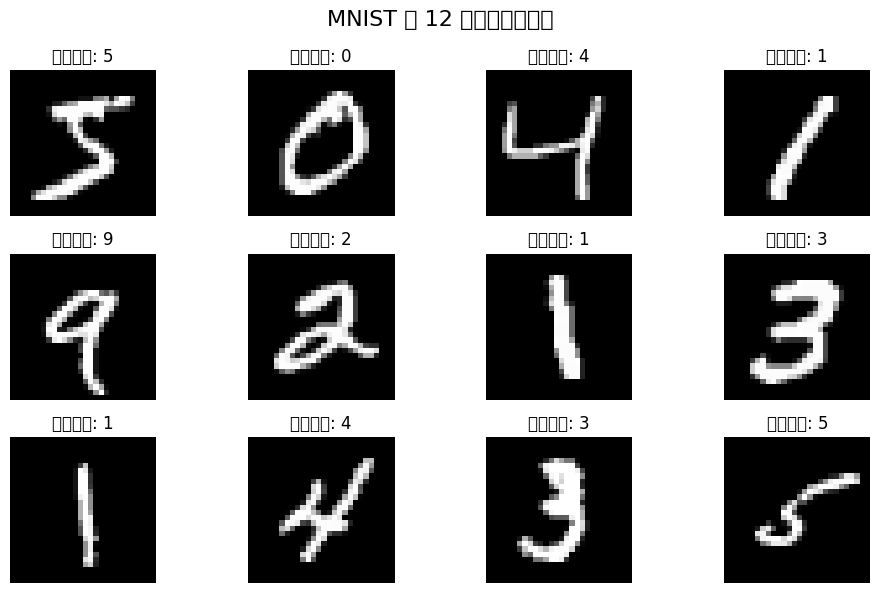

In [2]:
# e. 載入 MNIST 資料, 看前 12 張手寫數字影像

# 資料轉換預處理
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 下載訓練集與測試集
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

# 顯示前 12 張訓練集影像
plt.figure(figsize=(10, 6))
for i in range(12):
    image, label = train_dataset[i]
    plt.subplot(3, 4, i + 1)
    # 反向正規化還原像素值顯示
    img_show = image.squeeze() * 0.3081 + 0.1307
    plt.imshow(img_show, cmap='gray')
    plt.title(f"真實標籤: {label}")
    plt.axis('off')

plt.suptitle("MNIST 前 12 張手寫數字範例", fontsize=16)
plt.tight_layout()
plt.show()

In [3]:
# f. 定義 LeNet-5 模型

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        # C1: 輸入 1x28x28, 輸出 6x28x28 (Padding=2)
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.act1 = nn.ReLU()
        # S2: 平均池化，輸出 6x14x14
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)

        # C3: 輸出 16x10x10
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.act2 = nn.ReLU()
        # S4: 平均池化，輸出 16x5x5
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)

        # 全連接層
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.act3 = nn.ReLU()
        self.fc2 = nn.Linear(120, 84)
        self.act4 = nn.ReLU()
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool1(self.act1(self.conv1(x)))
        x = self.pool2(self.act2(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = self.act3(self.fc1(x))
        x = self.act4(self.fc2(x))
        x = self.fc3(x)
        return x

model = LeNet5().to(device)
print(model)

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (act1): ReLU()
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (act2): ReLU()
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (act3): ReLU()
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (act4): ReLU()
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [4]:
# g. 訓練 10 世代 (並記錄訓練過程資訊)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
train_losses = []
train_accuracies = []

print("開始訓練模型...")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = 100. * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")
print("訓練完成！")

開始訓練模型...
Epoch [1/10] - Loss: 0.2898 - Accuracy: 91.27%
Epoch [2/10] - Loss: 0.0868 - Accuracy: 97.22%
Epoch [3/10] - Loss: 0.0596 - Accuracy: 98.14%
Epoch [4/10] - Loss: 0.0459 - Accuracy: 98.54%
Epoch [5/10] - Loss: 0.0375 - Accuracy: 98.81%
Epoch [6/10] - Loss: 0.0319 - Accuracy: 98.97%
Epoch [7/10] - Loss: 0.0272 - Accuracy: 99.13%
Epoch [8/10] - Loss: 0.0237 - Accuracy: 99.24%
Epoch [9/10] - Loss: 0.0199 - Accuracy: 99.36%
Epoch [10/10] - Loss: 0.0182 - Accuracy: 99.41%
訓練完成！


/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 19990 (\N{CJK UNIFIED IDEOGRAPH-4E16}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 20195 (\N{CJK UNIFIED IDEOGRAPH-4EE3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 25613 (\N{CJK UNIFIED IDEOGRAPH-640D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 35347 (\N{CJK UNIFIED IDEOGRAPH-8A13}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/234463511.py:23: UserWarning: Glyph 32244 (\N{CJK UNIFIED IDEOGRAPH-7DF4}) missi

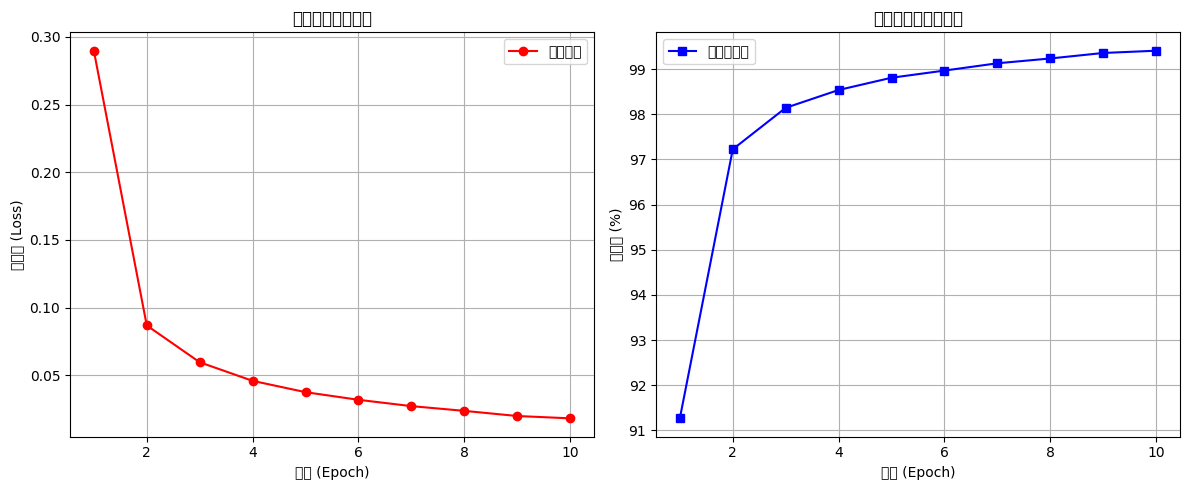

In [5]:
# h. 繪製訓練過程損失與準確率曲線

plt.figure(figsize=(12, 5))

# 損失曲線
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, marker='o', color='red', label='訓練損失')
plt.title('訓練損失變化曲線')
plt.xlabel('世代 (Epoch)')
plt.ylabel('損失值 (Loss)')
plt.grid(True)
plt.legend()

# 準確度曲線
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_accuracies, marker='s', color='blue', label='訓練準確率')
plt.title('訓練準確率變化曲線')
plt.xlabel('世代 (Epoch)')
plt.ylabel('準確率 (%)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23526 (\N{CJK UNIFIED IDEOGRAPH-5BE6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27161 (\N{CJK UNIFIED IDEOGRAPH-6A19}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 31844 (\N{CJK UNIFIED IDEOGRAPH-7C64}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  fig.canvas

測試集總準確率: 98.71%


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


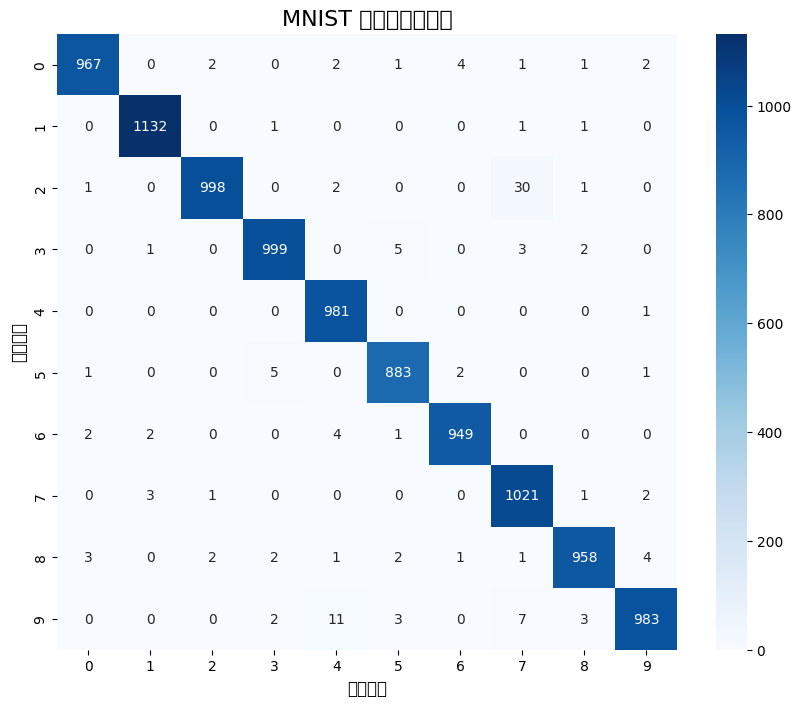

In [6]:
# i. 繪製混淆矩陣

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
test_acc = 100. * np.sum(all_preds == all_labels) / len(all_labels)
print(f"測試集總準確率: {test_acc:.2f}%")

# 繪製矩陣熱圖
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=list(range(10)), yticklabels=list(range(10)))
plt.title('MNIST 測試集混淆矩陣', fontsize=16)
plt.xlabel('預測標籤', fontsize=12)
plt.ylabel('真實標籤', fontsize=12)
plt.show()

/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 23526 (\N{CJK UNIFIED IDEOGRAPH-5BE6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/3113442321.py:27: UserWarning: Glyph 24373 (\N{CJK UNIFIED IDEOGRAPH-5F35}

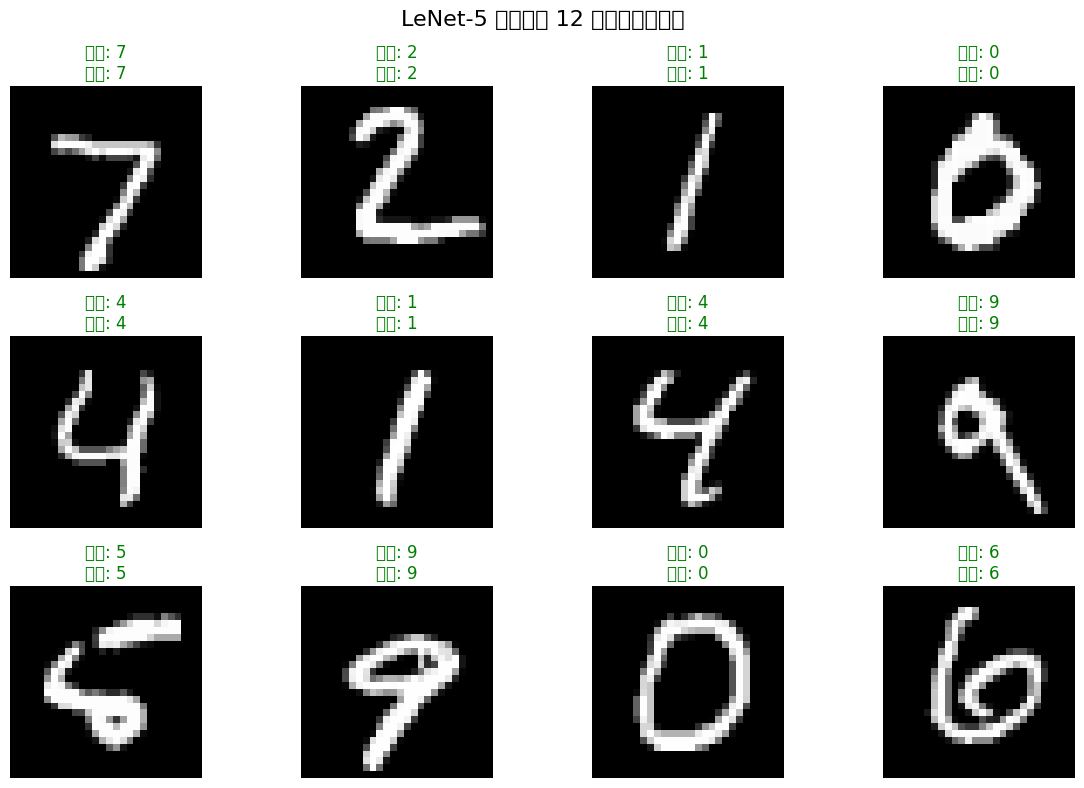

In [7]:
# j. 用你訓練的模型預測 12 張手寫數字範例

model.eval()
plt.figure(figsize=(12, 8))

# 取出測試集前 12 張影像進行測試與可視化
with torch.no_grad():
    for i in range(12):
        image, label = test_dataset[i]
        # 增加 batch 維度並送入裝置
        input_tensor = image.unsqueeze(0).to(device)
        output = model(input_tensor)
        _, predicted = output.max(1)
        pred_label = predicted.item()

        # 繪圖
        plt.subplot(3, 4, i + 1)
        img_show = image.squeeze() * 0.3081 + 0.1307
        plt.imshow(img_show, cmap='gray')

        # 若預測正確顯示綠色，預測錯誤顯示紅色
        color = 'green' if pred_label == label else 'red'
        plt.title(f"真實: {label}\n預測: {pred_label}", color=color, fontsize=12)
        plt.axis('off')

plt.suptitle("LeNet-5 模型預測 12 張手寫數字結果", fontsize=16)
plt.tight_layout()
plt.show()

請上傳您自己手寫數字的圖片 (JPG/PNG)：


Saving S__32407562_0.jpg to S__32407562_0.jpg
Saving S__32407557_0.jpg to S__32407557_0.jpg
Saving S__32407558_0.jpg to S__32407558_0.jpg
Saving S__32407559_0.jpg to S__32407559_0.jpg
Saving S__32407560_0.jpg to S__32407560_0.jpg
Saving S__32407561_0.jpg to S__32407561_0.jpg
Saving S__32407563_0.jpg to S__32407563_0.jpg
Saving S__32407564_0.jpg to S__32407564_0.jpg
Saving S__32407565_0.jpg to S__32407565_0.jpg
Saving S__32407556_0.jpg to S__32407556_0.jpg


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24744 (\N{CJK UNIFIED IDEOGRAPH-60A8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20659 (\N{CJK UNIFIED IDEOGRAPH-50B3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  fig.canvas

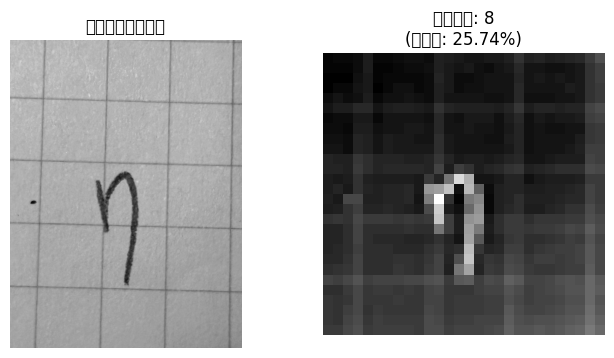

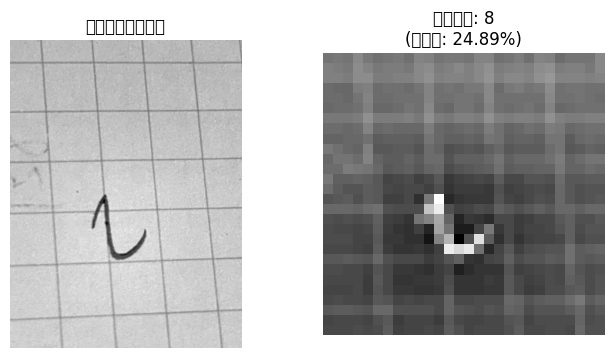

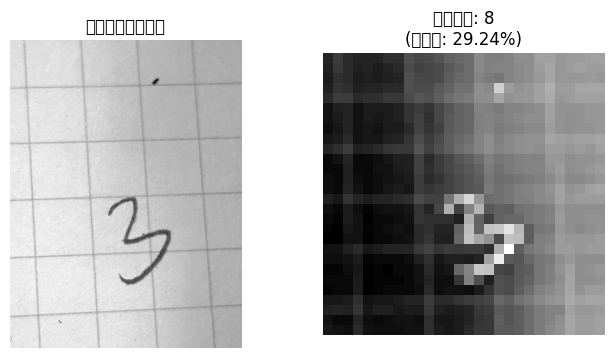

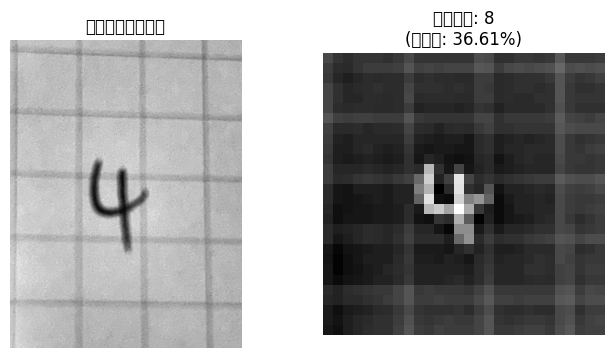

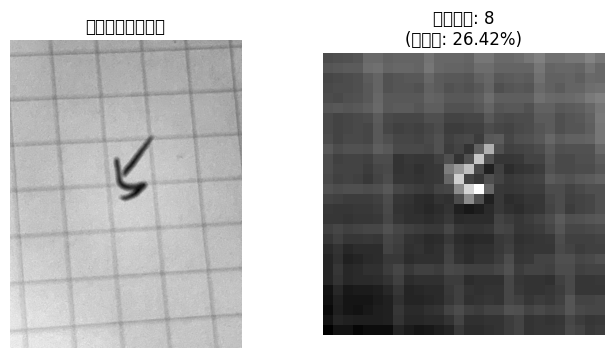

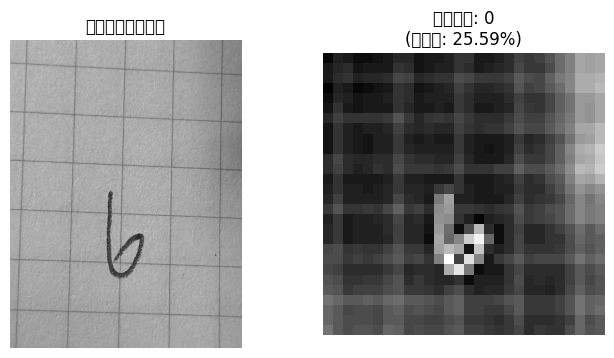

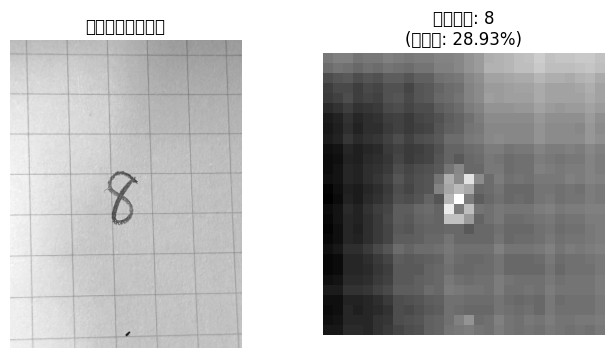

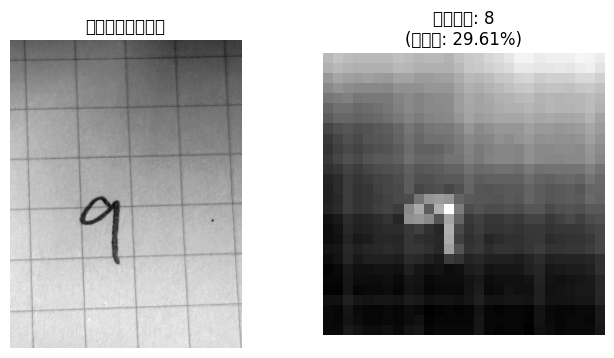

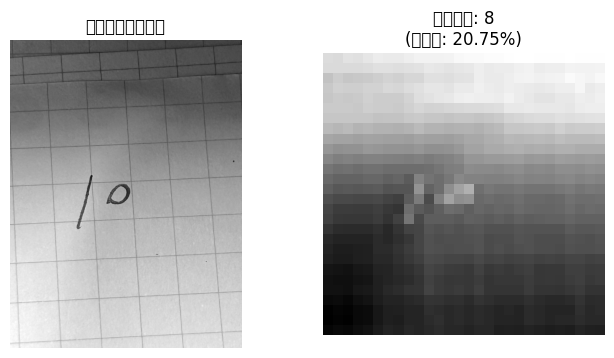

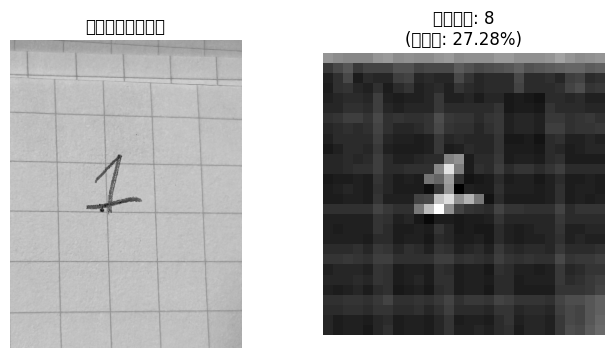

In [8]:
# 匯入並預測自己手寫的數字
from google.colab import files
from PIL import Image, ImageOps
import io

print("請上傳您自己手寫數字的圖片 (JPG/PNG)：")
uploaded = files.upload()

for fn in uploaded.keys():
    # 讀取上傳的圖片並轉換成灰階
    raw_img = Image.open(io.BytesIO(uploaded[fn])).convert('L')

    # 調整大小至 28x28
    img_resized = raw_img.resize((28, 28), Image.Resampling.LANCZOS)

    # 預處理：MNIST 是黑底白字。如果是白底黑字，自動進行反轉
    # 我們藉由檢查四個角落的平均像素值來決定是否反轉
    corner_pixels = [
        img_resized.getpixel((0, 0)),
        img_resized.getpixel((0, 27)),
        img_resized.getpixel((27, 0)),
        img_resized.getpixel((27, 27))
    ]
    if np.mean(corner_pixels) > 127:
        img_input = ImageOps.invert(img_resized)
    else:
        img_input = img_resized

    # 轉成 NumPy 陣列顯示
    img_np = np.array(img_input)

    # 進行與訓練相同的標準化轉換
    # transforms.ToTensor() 會將 0-255 縮放到 0-1
    img_tensor = torch.FloatTensor(img_np) / 255.0
    img_tensor = (img_tensor - 0.1307) / 0.3081
    img_tensor = img_tensor.unsqueeze(0).unsqueeze(0).to(device) # 增加 Batch 與 Channel 維度: [1, 1, 28, 28]

    # 模型預測
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        probabilities = torch.nn.functional.softmax(output, dim=1)
        _, predicted = output.max(1)
        pred_label = predicted.item()
        confidence = probabilities[0][pred_label].item() * 100

    # 顯示結果
    plt.figure(figsize=(8, 4))

    # 原始上傳圖
    plt.subplot(1, 2, 1)
    plt.imshow(raw_img, cmap='gray')
    plt.title("您上傳的原始圖片")
    plt.axis('off')

    # 餵給模型的預處理圖
    plt.subplot(1, 2, 2)
    plt.imshow(img_np, cmap='gray')
    plt.title(f"預測結果: {pred_label}\n(信心度: {confidence:.2f}%)")
    plt.axis('off')

    plt.show()

正在為您統整這 10 張手寫圖片的預測結果...


/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 22294 (\N{CJK UNIFIED IDEOGRAPH-5716}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 29255 (\N{CJK UNIFIED IDEOGRAPH-7247}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 38928 (\N{CJK UNIFIED IDEOGRAPH-9810}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 28204 (\N{CJK UNIFIED IDEOGRAPH-6E2C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 24744 (\N{CJK UNIFIED IDEOGRAPH-60A8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3270/811504657.py:61: UserWarning: Glyph 25163 (\N{CJK UNIFIED IDEOGRAPH-624B}) missi

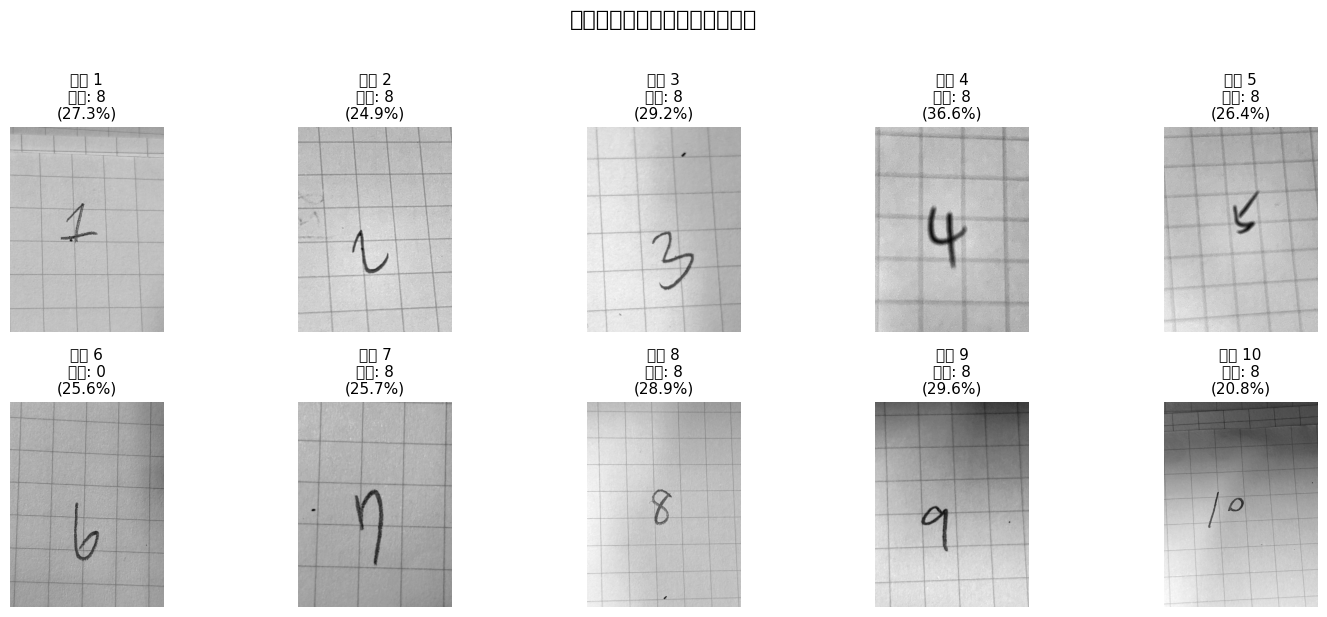

In [9]:
import os
import math

# 收集所有上傳並保存好的圖片路徑
uploaded_files = sorted([f for f in os.listdir('/content') if f.startswith('S__324075') and f.endswith(('.jpg', '.png', '.jpeg'))])
num_files = len(uploaded_files)

if num_files == 0:
    print("未偵測到已上傳的手寫數字圖片，請確保您已執行前一個儲存格並完成上傳。")
else:
    # 計算網格排版 (每行最多 5 張圖片)
    cols = min(5, num_files)
    rows = math.ceil(num_files / cols)

    plt.figure(figsize=(15, 3 * rows))
    model.eval()

    print(f"正在為您統整這 {num_files} 張手寫圖片的預測結果...")

    for idx, fn in enumerate(uploaded_files):
        # 讀取並轉換為灰階
        filepath = os.path.join('/content', fn)
        raw_img = Image.open(filepath).convert('L')

        # 調整大小為 28x28
        img_resized = raw_img.resize((28, 28), Image.Resampling.LANCZOS)

        # 判斷是否需要反轉顏色 (MNIST 為黑底白字)
        corner_pixels = [
            img_resized.getpixel((0, 0)),
            img_resized.getpixel((0, 27)),
            img_resized.getpixel((27, 0)),
            img_resized.getpixel((27, 27))
        ]
        if np.mean(corner_pixels) > 127:
            img_input = ImageOps.invert(img_resized)
        else:
            img_input = img_resized

        # 影像標準化
        img_np = np.array(img_input)
        img_tensor = torch.FloatTensor(img_np) / 255.0
        img_tensor = (img_tensor - 0.1307) / 0.3081
        img_tensor = img_tensor.unsqueeze(0).unsqueeze(0).to(device)

        # 進行預測
        with torch.no_grad():
            output = model(img_tensor)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            _, predicted = output.max(1)
            pred_label = predicted.item()
            confidence = probabilities[0][pred_label].item() * 100

        # 繪製子圖
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(raw_img, cmap='gray')
        plt.title(f"圖片 {idx+1}\n預測: {pred_label}\n({confidence:.1f}%)", fontsize=11)
        plt.axis('off')

    plt.suptitle("您的手寫數字圖片預測統整結果", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()